## **Messwerte (Kurzschluss)**

In [155]:
import numpy as np


f_1 = 130 #Erste Frequenz in Hz
f_1_Fehler = 1
omega_1 = f_1 * 2*np.pi
omega_1_Fehler = f_1_Fehler * 2*np.pi

N_1 = 50 #Primärwindungszahl
N_2 = np.array([15, 40, 60, 80 ,85, 100, 120, 140, 170, 200, 240, 290, 350, 420, 500]) #Sekundärwindungszahl

U1_f1 = np.array([0.182, 0.105, 0.068, 0.050 ,0.047, 0.038, 0.033, 0.029, 0.026, 0.039, 0.022,0.021, 0.020, 0.019, 0.019]) #Primärspannung bei Frequenz 1 in Volt
U1_f1_Fehler = 0.002

I1_f1 = np.array([30.2, 30.7, 31.3, 31.6 ,31.6, 31.8, 31.9, 31.9, 32.0, 32.1, 32.1, 32.1, 32.1, 32.1, 32.2]) *10**(-3) #Primärstrom bei Frequenz 1 in Ampere
I1_f1_Fehler = 0.2e-3

I2_f1 = np.array([28.6, 28.3, 22.4, 18.2, 18.2, 15.0, 12.8, 11.1, 9.2, 7.8, 6.5, 5.4, 4.5, 3.8, 3.2]) *10**(-3)#Sekundärstrom bei Frequenz 1 in Ampere
I2_f1_Fehler = 0.2e-3



"""-----------------------------------------------------------------------------------------------------------------------------------"""



f_2 = 320 #Zweite Frequenz in Hz
f_2_Fehler = 1
omega_2 = f_2 * 2*np.pi
omega_2_Fehler = f_2_Fehler * 2*np.pi

U1_f2 = np.array([0.271, 0.121, 0.072, 0.052 ,0.050, 0.038, 0.033, 0.029, 0.026, 0.024, 0.022, 0.021, 0.020, 0.020, 0.019]) #Primärspannung bei Frequenz 2 in Volt
U1_f2_Fehler = 0.002

I1_f2 = np.array([28.1, 30.1, 31.0, 31.3, 31.4, 31.6, 31.7, 31.7, 31.8, 31.9, 31.9, 31.9, 31.9, 32.0, 32.0])*10**(-3) #Primärstrom bei Frequenz 2 in Ampere
I1_f2_Fehler = 0.2e-3

I2_f2 = np.array([42.6, 32.7, 22.9, 18.9, 18.7, 15.7, 12.8, 11.0, 9.1, 7.7, 6.4, 5.3, 4.3, 3.6, 3.0])*10**(-3) #Sekundärstrom bei Frequenz 2 in Ampere
I2_f2_Fehler = 0.2e-3


## **Berechnung der Induktivität für f_1**

In [156]:
import sympy as sp
from Skripte.Fehlerfortpflanzung import Gaußfehler
from IPython.display import display

%store -r L12_f1
%store -r L12_f1_Fehler

#Berechnung von L2
# noinspection PyUnresolvedReferences
L2_f1 = L12_f1 * I1_f1 / I2_f1
L2_f1_Fehler = np.zeros(len(L2_f1), dtype = float)

%store L2_f1

L12p, I1p, I2p = sp.symbols("L_12, I_1, I_2")
expr1 = L12p * I1p / I2p
display(expr1)
Variablen = np.array([L12p, I1p, I2p])

print(f"Induktivitäten für f_1 = {f_1}Hz :")
for i in range(len(L2_f1)):
    # noinspection PyUnresolvedReferences
    L2_f1_Fehler[i] = Gaußfehler(expr1, Variablen, np.array([L12_f1[i], I1_f1[i], I2_f1[i]]), np.array([L12_f1_Fehler[i], I1_f1_Fehler, I2_f1_Fehler]))
    print(f"für N_2 = {N_2[i]} gilt: L_2 = ({L2_f1[i]} +/- {L2_f1_Fehler[i]})H")



Stored 'L2_f1' (ndarray)


I_1*L_12/I_2

Induktivitäten für f_1 = 130Hz :
für N_2 = 15 gilt: L_2 = (0.01526290077030087 +/- 0.00022813586508035937)H
für N_2 = 40 gilt: L_2 = (0.019621513497162655 +/- 0.0002858613857561032)H
für N_2 = 60 gilt: L_2 = (0.030351076140187196 +/- 0.00046484402368504086)H
für N_2 = 80 gilt: L_2 = (0.04402159847154446 +/- 0.0007251091285582775)H
für N_2 = 85 gilt: L_2 = (0.05348418505888579 +/- 0.0008758769340632654)H
für N_2 = 100 gilt: L_2 = (0.0766913565977701 +/- 0.0013780891438687774)H
für N_2 = 120 gilt: L_2 = (0.1083635234913779 +/- 0.002133256731603532)H
für N_2 = 140 gilt: L_2 = (0.15095045649877817 +/- 0.0032621122273501345)H
für N_2 = 170 gilt: L_2 = (0.22033404140200682 +/- 0.005459670880819832)H
für N_2 = 200 gilt: L_2 = (0.3127019452609498 +/- 0.008834353860816772)H
für N_2 = 240 gilt: L_2 = (0.44467386810496795 +/- 0.014661629333790262)H
für N_2 = 290 gilt: L_2 = (0.02159803225526079 +/- 0.0009620090174849129)H
für N_2 = 350 gilt: L_2 = (0.05155356394842684 +/- 0.002436889172409467)H
f

## **Berechnung der Induktivität für f_2**

In [157]:
%store -r L12_f2
%store -r L12_f2_Fehler

#Berechnung von L2
# noinspection PyUnresolvedReferences
L2_f2 = L12_f2 * I1_f2 / I2_f2
L2_f2_Fehler = np.zeros(len(L2_f2), dtype = float)

%store L2_f2

L12p, I1p, I2p = sp.symbols("L_12, I_1, I_2")
expr1 = L12p * I1p / I2p
display(expr1)
Variablen = np.array([L12p, I1p, I2p])

print(f"Induktivitäten für f_1 = {f_2}Hz :")
for i in range(len(L2_f2)):
    # noinspection PyUnresolvedReferences
    L2_f2_Fehler[i] = Gaußfehler(expr1, Variablen, np.array([L12_f2[i], I1_f2[i], I2_f2[i]]), np.array([L12_f2_Fehler[i], I1_f2_Fehler, I2_f2_Fehler]))
    print(f"für N_2 = {N_2[i]} gilt: L_2 = ({L2_f2[i]} +/- {L2_f2_Fehler[i]})H")

Stored 'L2_f2' (ndarray)


I_1*L_12/I_2

Induktivitäten für f_1 = 320Hz :
für N_2 = 15 gilt: L_2 = (0.009004481838942969 +/- 0.00010632964662523482)H
für N_2 = 40 gilt: L_2 = (0.01573126202931158 +/- 0.0001900050953128539)H
für N_2 = 60 gilt: L_2 = (0.02776687282865345 +/- 0.00037348430538146734)H
für N_2 = 80 gilt: L_2 = (0.039664624599529116 +/- 0.0005816545030338961)H
für N_2 = 85 gilt: L_2 = (0.04880522214774223 +/- 0.0007181076689080003)H
für N_2 = 100 gilt: L_2 = (0.06876035273736025 +/- 0.0011160952980787953)H
für N_2 = 120 gilt: L_2 = (0.10046115654115145 +/- 0.00186535302182622)H
für N_2 = 140 gilt: L_2 = (0.14129682981661396 +/- 0.002933283872912111)H
für N_2 = 170 gilt: L_2 = (0.20708376392480657 +/- 0.005000153420272713)H
für N_2 = 200 gilt: L_2 = (0.29519049412117615 +/- 0.008213872660748564)H
für N_2 = 240 gilt: L_2 = (0.4219616592945031 +/- 0.013842071373289196)H
für N_2 = 290 gilt: L_2 = (0.019107697779373725 +/- 0.0007754109499824761)H
für N_2 = 350 gilt: L_2 = (0.04841110509735384 +/- 0.0023176346397474723)H

## **Kopplungsgrad aus linearer Regression**

I_1/I_2

Kopplungsgrad für f_1 = 130Hz: kappa = 0.9519727489402375 +/- 0.015508538198204757
Kopplungsgrad für f_2 = 320Hz: kappa = 0.9713609779369707 +/- 0.015701108764977594


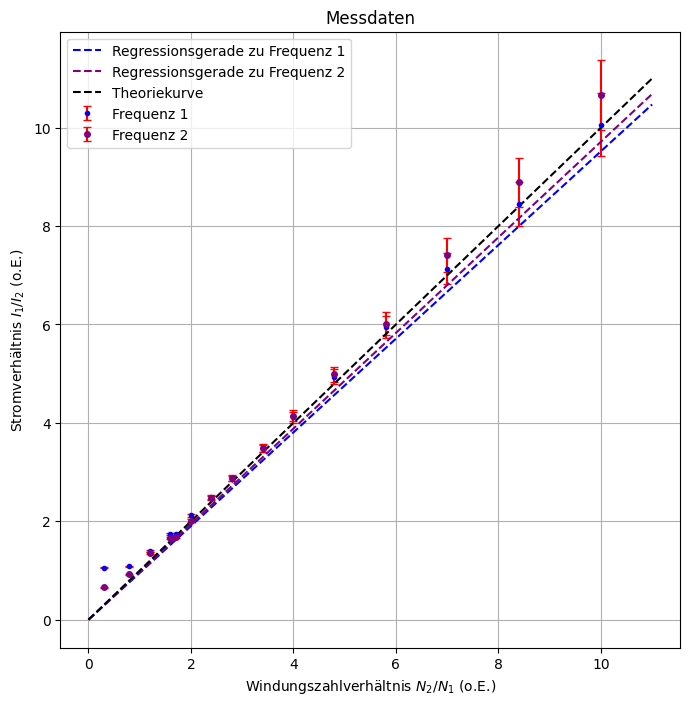

In [158]:

import scipy.optimize
import matplotlib.pyplot as plt

N_Ratio = N_2 / N_1

I1p, I2p = sp.symbols("I_1, I_2")
expr3 = I1p / I2p
display(expr3)
Variablen = np.array([I1p, I2p])

#Frequenz 1
I_Ratio_f1 = I1_f1 / I2_f1
I_Ratio_f1_Fehler = np.zeros(len(I_Ratio_f1), dtype = float)

for i in range(len(I_Ratio_f1_Fehler)):
    I_Ratio_f1_Fehler[i] = Gaußfehler(expr3, Variablen, np.array([I1_f1[i], I2_f1[i]]), np.array([I1_f1_Fehler, I2_f1_Fehler]))

#Frequenz 2
I_Ratio_f2 = I1_f2 / I2_f2
I_Ratio_f2_Fehler = np.zeros(len(I_Ratio_f2), dtype = float)

for i in range(len(I_Ratio_f2_Fehler)):
    I_Ratio_f2_Fehler[i] = Gaußfehler(expr3, Variablen, np.array([I1_f2[i], I2_f2[i]]), np.array([I1_f2_Fehler, I2_f2_Fehler]))

#Lineare Regression

def f(x,k,c):
    return k*x +c #Fit Funktion

coefficients1, pcov1 = scipy.optimize.curve_fit(f, N_Ratio[2:], I_Ratio_f1[2:], sigma= I_Ratio_f1_Fehler[2:], absolute_sigma= True)
kappa_1 = coefficients1[0]
kappa_1_Fehler = np.sqrt(pcov1[0,0])
c_1 = 0

print(f"Kopplungsgrad für f_1 = {f_1}Hz: kappa = {kappa_1} +/- {kappa_1_Fehler}")

coefficients2, pcov2 = scipy.optimize.curve_fit(f, N_Ratio[2:], I_Ratio_f2[2:], sigma= I_Ratio_f2_Fehler[2:], absolute_sigma= True)
kappa_2 = coefficients2[0]
kappa_2_Fehler = np.sqrt(pcov2[0,0])
c_2 = 0

print(f"Kopplungsgrad für f_2 = {f_2}Hz: kappa = {kappa_2} +/- {kappa_2_Fehler}")

#Plot
fig, ax1 = plt.subplots(1, 1, figsize=(8, 8))

ax1.errorbar(N_Ratio, I_Ratio_f1, yerr=I_Ratio_f1_Fehler, fmt="o", label="Frequenz 1", color="blue", markersize=3, capsize=3, ecolor="r")
ax1.errorbar(N_Ratio, I_Ratio_f2, yerr=I_Ratio_f2_Fehler, fmt="o", label="Frequenz 2", color="purple", markersize=4, capsize=3, ecolor="r")

xwerte = np.linspace(0, np.max(N_Ratio)*1.1, 500)
ax1.plot(xwerte, kappa_1*xwerte + c_1, color = "blue", linestyle = "--", label = "Regressionsgerade zu Frequenz 1")
ax1.plot(xwerte, kappa_2*xwerte + c_2, color = "purple", linestyle = "--", label = "Regressionsgerade zu Frequenz 2")

ax1.plot(xwerte, xwerte, color = "black", linestyle = "--", label = "Theoriekurve")

ax1.set_xlabel(r"Windungszahlverhältnis $N_2/N_1$ (o.E.)")
ax1.set_ylabel(r"Stromverhältnis $I_1/I_2$ (o.E.)")
ax1.grid(True)
ax1.set_title("Messdaten")
ax1.legend()


## **Kopplungsgrad aus allen Induktivitäten Frequenz 1**

In [159]:
%store -r L1_f1
%store -r L1_f1_Fehler


#Frequenz 1

# noinspection PyUnresolvedReferences
kappa_f1 = L12_f1 / np.sqrt(L1_f1 * L2_f1)
kappa_f1_Fehler = np.zeros(len(kappa_f1), dtype = float)

L1p, L2p, L12p = sp.symbols("L_1, L_2, L_12")
expr4 = L12p / sp.sqrt(L1p * L2p)
display(expr4)
Variablen = np.array([L1p, L2p, L12p])

print(f"Kopplungsgradefür f_1 = {f_1}Hz :")
for i in range(len(kappa_f1)):
    # noinspection PyUnresolvedReferences
    kappa_f1_Fehler[i] = Gaußfehler(expr4, Variablen, np.array([L1_f1[i], L2_f1[i], L12_f1[i]]), np.array([L1_f1_Fehler[i], L2_f1_Fehler[i], L12_f1_Fehler[i]]))
    print(f"für N_2 = {N_2[i]} gilt: kappa = ({kappa_f1[i]} +/- {kappa_f1_Fehler[i]})")




L_12/sqrt(L_1*L_2)

Kopplungsgradefür f_1 = 130Hz :
für N_2 = 15 gilt: kappa = (1.222295169221967 +/- 0.018548589545217768)
für N_2 = 40 gilt: kappa = (1.3490025685339766 +/- 0.019858492890888122)
für N_2 = 60 gilt: kappa = (1.3025343725065717 +/- 0.019162645383577846)
für N_2 = 80 gilt: kappa = (1.2624543243203687 +/- 0.01881465872159921)
für N_2 = 85 gilt: kappa = (1.3915392530568103 +/- 0.020554957649566948)
für N_2 = 100 gilt: kappa = (1.3646956710420213 +/- 0.020699505106466527)
für N_2 = 120 gilt: kappa = (1.3799371616492286 +/- 0.021588774652631565)
für N_2 = 140 gilt: kappa = (1.4123683470108261 +/- 0.022930322677635777)
für N_2 = 170 gilt: kappa = (1.40986365200376 +/- 0.02440440593650429)
für N_2 = 200 gilt: kappa = (1.4195586047399842 +/- 0.026374488116293913)
für N_2 = 240 gilt: kappa = (1.4106770247165594 +/- 0.028811141108799402)
für N_2 = 290 gilt: kappa = (0.2582820857827493 +/- 0.008617294787764561)
für N_2 = 350 gilt: kappa = (0.3325334155329656 +/- 0.009537428357174655)
für N_2 = 420 gi

## **Kopplungsgrad aus allen Induktivitäten Frequenz 2**

In [160]:
%store -r L1_f2
%store -r L1_f2_Fehler

#Frequenz 2

# noinspection PyUnresolvedReferences
kappa_f2 = L12_f2 / np.sqrt(L1_f2 * L2_f2)
kappa_f2_Fehler = np.zeros(len(kappa_f2), dtype = float)

L1p, L2p, L12p = sp.symbols("L_1, L_2, L_12")
expr4 = L12p / sp.sqrt(L1p * L2p)
display(expr4)
Variablen = np.array([L1p, L2p, L12p])

print(f"Kopplungsgradefür f_2 = {f_2}Hz :")
for i in range(len(kappa_f2)):
    # noinspection PyUnresolvedReferences
    kappa_f2_Fehler[i] = Gaußfehler(expr4, Variablen, np.array([L1_f2[i], L2_f2[i], L12_f2[i]]), np.array([L1_f2_Fehler[i], L2_f2_Fehler[i], L12_f2_Fehler[i]]))
    print(f"für N_2 = {N_2[i]} gilt: kappa = ({kappa_f2[i]} +/- {kappa_f2_Fehler[i]})")

L_12/sqrt(L_1*L_2)

Kopplungsgradefür f_2 = 320Hz :
für N_2 = 15 gilt: kappa = (1.5490580407085566 +/- 0.017025576962955483)
für N_2 = 40 gilt: kappa = (1.4672296256524089 +/- 0.016072278854991705)
für N_2 = 60 gilt: kappa = (1.3254773842633758 +/- 0.014963864034377874)
für N_2 = 80 gilt: kappa = (1.2949535445602822 +/- 0.015056732021999622)
für N_2 = 85 gilt: kappa = (1.4167073704962256 +/- 0.016452084646018716)
für N_2 = 100 gilt: kappa = (1.4028675374157324 +/- 0.01696228675371605)
für N_2 = 120 gilt: kappa = (1.3781130401171218 +/- 0.01776702623739288)
für N_2 = 140 gilt: kappa = (1.4045418364650266 +/- 0.019233623404721914)
für N_2 = 170 gilt: kappa = (1.4022399798422611 +/- 0.021050860690894554)
für N_2 = 200 gilt: kappa = (1.4121677007773623 +/- 0.023336050449089592)
für N_2 = 240 gilt: kappa = (1.4033333122437432 +/- 0.026196287528506414)
für N_2 = 290 gilt: kappa = (0.2473001707721032 +/- 0.006129981400023554)
für N_2 = 350 gilt: kappa = (0.3193635290736766 +/- 0.008336930830546065)
für N_2 = 420